# Neural networks, blends and stacking: completing the ensemble comparison
**Companion notebook to the main project** (`ensemble_tourism_forecasting.ipynb`)

The main notebook compared bagging, boosting, voting, stacking and trend-plus-ensemble hybrids. This notebook adds the models that connect the project to the **interactive dashboard**:
1. An **ANN** (artificial neural network)
2. **Blends**: Random Forest + CatBoost, CatBoost + ANN, Random Forest + ANN
3. **Stacking** with a neural network inside: Random Forest + CatBoost + ANN, combined by a Ridge meta-model
4. **Hybrids** with an ANN and with CatBoost
5. A **"glass ceiling" experiment** that shows, visually, why tree models fail at record-high months, and why an ANN or a hybrid does not

All models use the **same data, features, train/test split and metrics** as the main notebook, so every number can be compared directly.

*Live dashboard:* https://sri-lanka-tourism-forecaster.streamlit.app (the dashboard uses the model set defined in this notebook).

## 1. Setup and data

In [1]:
!pip install -q catboost

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from sklearn.base import clone, BaseEstimator, RegressorMixin
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor,
                              VotingRegressor, StackingRegressor)
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True

In [3]:
DATA_URL = "https://raw.githubusercontent.com/RDHMRambandara/sri-lanka-tourism-ensemble/main/data/tourism_monthly_2010_2026.csv"
df = pd.read_csv(DATA_URL, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
print(df.shape)

(199, 3)


**Features and split.** This is exactly the feature code of the main notebook: calendar and monsoon-season features, the shock flag, lags and rolling averages built **only from past months**, and last month's exchange rate. Training is January 2011 to December 2023; testing is January 2024 to July 2026. Every month is forecast **one month ahead**.

In [4]:
df["month"] = df["date"].dt.month
df["quarter"] = df["date"].dt.quarter
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

def monsoon_season(m):
    if m in (5, 6, 7, 8, 9): return "SW_monsoon"
    if m in (12, 1, 2):      return "NE_monsoon"
    return "Inter_monsoon"

df["season"] = df["month"].map(monsoon_season)
df = pd.concat([df, pd.get_dummies(df["season"], prefix="season", dtype=int)], axis=1)
df["shock"] = ((df["date"] >= "2019-04-01") & (df["date"] <= "2022-12-01")).astype(int)

for k in (1, 2, 3, 12):
    df[f"lag_{k}"] = df["arrivals"].shift(k)
df["roll3"] = df["arrivals"].shift(1).rolling(3).mean()
df["roll12"] = df["arrivals"].shift(1).rolling(12).mean()
df["fx_lag1"] = df["usd_lkr"].shift(1)
df["fx_chg_lag1"] = df["usd_lkr"].pct_change().shift(1)
df["t"] = np.arange(len(df))          # time index, only used in one feature test below

data = df.dropna().reset_index(drop=True)

features = ["month", "quarter", "month_sin", "month_cos",
            "season_SW_monsoon", "season_NE_monsoon", "season_Inter_monsoon", "shock",
            "lag_1", "lag_2", "lag_3", "lag_12", "roll3", "roll12", "fx_lag1", "fx_chg_lag1"]
target = "arrivals"

train = data[data["date"] < "2024-01-01"]
test = data[data["date"] >= "2024-01-01"]
print("Main split -> Train:", len(train), "months | Test:", len(test), "months")

Main split -> Train: 156 months | Test: 31 months


In [5]:
train = data[data["date"] < "2024-01-01"]
test = data[data["date"] >= "2024-01-01"]
X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]
print("Train:", len(train), "months | Test:", len(test), "months")

def evaluate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {"MAE": round(mean_absolute_error(y_true, y_pred)),
            "RMSE": round(mean_squared_error(y_true, y_pred) ** 0.5),
            "MAPE %": round(np.mean(np.abs((y_true - y_pred) / y_true)) * 100, 1)}

Train: 156 months | Test: 31 months


## 2. The neural network (ANN)
**What it is:** an artificial neural network is a stack of layers. Each layer multiplies the inputs by weights, adds them up and passes the result through a simple function (here ReLU, which outputs zero for negative values and the value itself otherwise). The weights are adjusted step by step to reduce the prediction error. Our network has two hidden layers (64 and 32 units).

**Two important details:**
- **Scaling.** Neural networks learn badly when inputs have very different sizes (month = 1 to 12, arrivals = 100,000+). So we scale every input to a similar range (`StandardScaler`), and we also scale the **target** (arrivals) with `TransformedTargetRegressor`. The predictions are converted back to tourists automatically.
- **Regularisation.** `alpha=0.01` adds a small penalty on large weights, to reduce overfitting on our small dataset (156 training months).

**Why we expect it to behave differently from trees:** a ReLU network is made of straight-line pieces, so outside the range it has seen it **continues in a straight line**, whereas a tree predicts a fixed average. This is the key difference for forecasting record-high months.

In [6]:
def make_ann():
    net = make_pipeline(StandardScaler(),
                        MLPRegressor(hidden_layer_sizes=(64, 32), alpha=0.01, max_iter=3000, random_state=42))
    return TransformedTargetRegressor(regressor=net, transformer=StandardScaler())

ann = make_ann().fit(X_train, y_train)
print("ANN on the test period:", evaluate(y_test, ann.predict(X_test)))

ANN on the test period: {'MAE': 18848, 'RMSE': 24330, 'MAPE %': np.float64(11.2)}


## 3. The full model set (the same as the dashboard)
| Family | Model | Idea |
|---|---|---|
| Baseline | Linear regression | straight-line trend |
| Bagging | Random Forest | a crowd of trees averaged |
| Boosting | CatBoost | trees that correct each other's mistakes |
| Neural network | ANN | smooth learned curves |
| Blend | RF + CatBoost, CatBoost + ANN, RF + ANN | simple average of two different models |
| Stacking | RF + CatBoost + ANN with a Ridge meta-model | a "manager" model learns how much to trust each one |
| Hybrid | Linear + RF, Linear + CatBoost, Linear + ANN, Linear + Voting(RF, ET, GB) | linear model for the trend, then a model on what it missed |

**Blend vs stacking:** a blend gives each model the same weight (a plain average). Stacking trains a final model (Ridge regression) that learns the weights. (As in the main notebook, scikit-learn creates the stacking inputs with 5 contiguous folds, which is not strictly time-ordered, so we read stacking results with some caution.)

In [7]:
class HybridRegressor(BaseEstimator, RegressorMixin):
    """Linear regression learns the trend; the model learns what the trend missed."""
    def __init__(self, model=None):
        self.model = model
    def fit(self, X, y):
        self.trend_ = LinearRegression().fit(X, y)
        self.model_ = clone(self.model).fit(X, y - self.trend_.predict(X))
        return self
    def predict(self, X):
        return self.trend_.predict(X) + self.model_.predict(X)

try:
    from catboost import CatBoostRegressor
    BOOST = "CatBoost"
    make_boost = lambda: CatBoostRegressor(iterations=300, learning_rate=0.05, depth=4, random_seed=42, verbose=0)
except Exception as e:
    print("CatBoost not available, using Gradient Boosting instead:", e)
    BOOST = "Gradient Boosting"
    make_boost = lambda: GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                   subsample=0.8, random_state=42)

make_rf = lambda: RandomForestRegressor(n_estimators=300, random_state=42)
make_et = lambda: ExtraTreesRegressor(n_estimators=200, random_state=42)
make_gb = lambda: GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3,
                                            subsample=0.8, random_state=42)
make_voting = lambda: VotingRegressor([("rf", make_rf()), ("et", make_et()), ("gb", make_gb())])

models = {
    "Linear regression": ("Baseline", LinearRegression()),
    "Random Forest": ("Bagging", make_rf()),
    BOOST: ("Boosting", make_boost()),
    "ANN (neural network)": ("Neural network", make_ann()),
    f"Blend: RF + {BOOST}": ("Blend", VotingRegressor([("rf", make_rf()), ("b", make_boost())])),
    f"Blend: {BOOST} + ANN": ("Blend", VotingRegressor([("b", make_boost()), ("ann", make_ann())])),
    "Blend: RF + ANN": ("Blend", VotingRegressor([("rf", make_rf()), ("ann", make_ann())])),
    f"Stacking: RF + {BOOST} + ANN": ("Stacking", StackingRegressor(
        estimators=[("rf", make_rf()), ("b", make_boost()), ("ann", make_ann())],
        final_estimator=RidgeCV(), cv=5)),
    "Hybrid: Linear + Random Forest": ("Hybrid", HybridRegressor(make_rf())),
    f"Hybrid: Linear + {BOOST}": ("Hybrid", HybridRegressor(make_boost())),
    "Hybrid: Linear + ANN": ("Hybrid", HybridRegressor(make_ann())),
    "Hybrid: Linear + Voting (RF+ET+GB)": ("Hybrid", HybridRegressor(make_voting())),
}
print(len(models), "models defined")

12 models defined


## 4. Main comparison on the test period (Jan 2024 to Jul 2026)

In [8]:
results, preds, family = {}, {}, {}
for name, (fam, m) in models.items():
    fitted = clone(m).fit(X_train, y_train)
    preds[name] = fitted.predict(X_test)
    results[name] = evaluate(y_test, preds[name])
    family[name] = fam
results["Naive (last month)"] = evaluate(y_test, test["lag_1"]); family["Naive (last month)"] = "Baseline"
results["Seasonal naive"] = evaluate(y_test, test["lag_12"]); family["Seasonal naive"] = "Baseline"

table = pd.DataFrame(results).T
table["Family"] = pd.Series(family)
table = table.sort_values("MAE")
table

,MAE,RMSE,MAPE %,Family
Hybrid: Linear + Voting (RF+ET+GB),13162.0,20491.0,7.8,Hybrid
Hybrid: Linear + CatBoost,15326.0,22312.0,9.1,Hybrid
Hybrid: Linear + Random Forest,15382.0,20832.0,9.1,Hybrid
Blend: CatBoost + ANN,16703.0,22213.0,9.6,Blend
Stacking: RF + CatBoost + ANN,17342.0,23224.0,9.9,Stacking
Hybrid: Linear + ANN,18028.0,24355.0,10.3,Hybrid
ANN (neural network),18848.0,24330.0,11.2,Neural network
CatBoost,20633.0,26659.0,11.1,Boosting
Blend: RF + ANN,22026.0,26517.0,11.7,Blend
Linear regression,22189.0,27071.0,13.2,Baseline


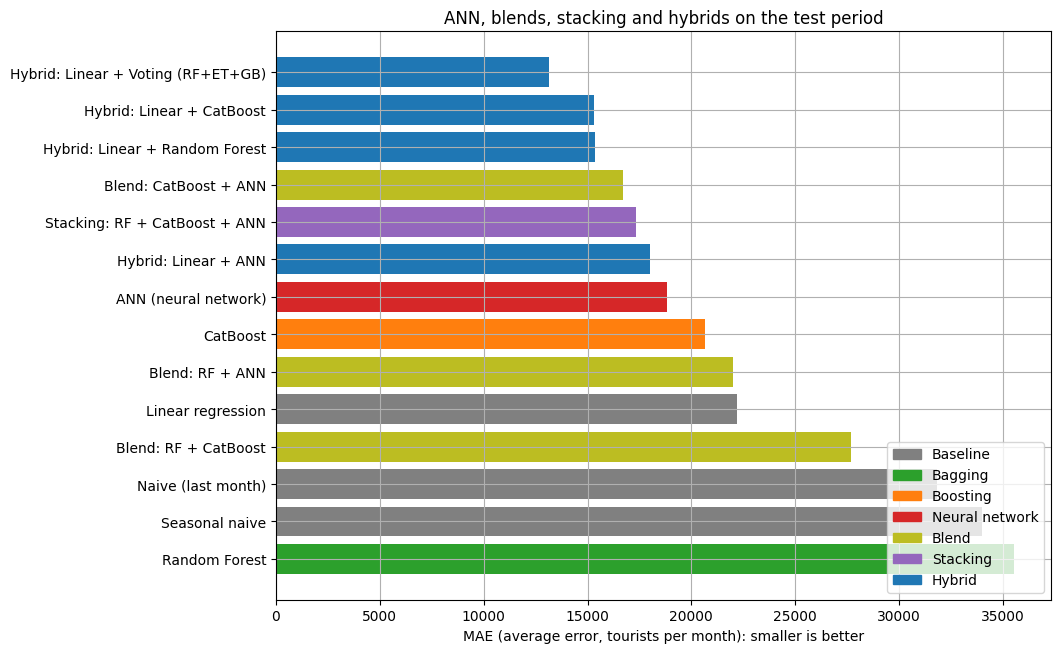

In [9]:
colors = {"Baseline": "gray", "Bagging": "tab:green", "Boosting": "tab:orange", "Neural network": "tab:red",
          "Blend": "tab:olive", "Stacking": "tab:purple", "Hybrid": "tab:blue"}
t = table.sort_values("MAE", ascending=False)
fig, ax = plt.subplots(figsize=(10, 0.42 * len(t) + 1.5))
ax.barh(t.index, t["MAE"], color=[colors[f] for f in t["Family"]])
ax.set_xlabel("MAE (average error, tourists per month): smaller is better")
ax.set_title("ANN, blends, stacking and hybrids on the test period")
ax.legend(handles=[Patch(color=c, label=f) for f, c in colors.items()], loc="lower right")
plt.show()

**What we found (from this run).** Each bar is a model's average error in tourists per month.
1. **Neural network vs trees.** The ANN (error about 18,800) is much better than the plain Random Forest (about 35,500), and also better than CatBoost (about 20,600) and linear regression (about 22,200). The reason is the straight-line behaviour explained in Section 2, which Section 6 tests directly.
2. **Blends.** *CatBoost + ANN* (about 16,700) is better than **both** of its members (CatBoost about 20,600, ANN about 18,800): two models that make different mistakes cancel some of each other's errors. *RF + ANN* (about 22,000) is better than the Random Forest but **worse than the ANN alone**, and *RF + CatBoost* (about 27,700) is worse than CatBoost alone. Averaging with a weak, ceiling-limited model drags the better model down.
3. **Stacking.** *RF + CatBoost + ANN* (about 17,300) beats every single raw model and two of the three blends, but not the best blend (CatBoost + ANN, about 16,700). In the main notebook, stacking three tree models gave about 27,000. Adding an ANN made stacking much better, because the "manager" now has one member that can follow a trend.
4. **Hybrids.** The tree hybrids are the best models (about 13,200 to 15,400; Linear + Voting is the best overall). The hybrid with an ANN (about 18,000) gives only a **small gain over the ANN alone** (about 18,800) and stays well behind the tree hybrids.

## 5. Is the ranking reliable? Rolling backtest
As in the main notebook, we repeat the test on five windows (2016, 2017, 2018, 2023 and 2024-26), always training on all data before the window.

In [10]:
windows = [("2016", "2016-01-01", "2017-01-01"), ("2017", "2017-01-01", "2018-01-01"),
           ("2018", "2018-01-01", "2019-01-01"), ("2023", "2023-01-01", "2024-01-01"),
           ("2024-26", "2024-01-01", "2100-01-01")]
bt = {}
for wname, start, end in windows:
    tr = data[data["date"] < start]
    te = data[(data["date"] >= start) & (data["date"] < end)]
    row = {"Naive (last month)": mean_absolute_error(te[target], te["lag_1"]),
           "Seasonal naive": mean_absolute_error(te[target], te["lag_12"])}
    for name, (fam, m) in models.items():
        row[name] = mean_absolute_error(te[target], clone(m).fit(tr[features], tr[target]).predict(te[features]))
    bt[wname] = row
    print("done:", wname)
backtest = pd.DataFrame(bt)
backtest["Mean MAE"] = backtest.mean(axis=1)
backtest["Mean rank"] = backtest[[w[0] for w in windows]].rank().mean(axis=1)
backtest = backtest.sort_values("Mean MAE")
backtest.round(0).assign(**{"Mean rank": backtest["Mean rank"].round(1)})

done: 2016
done: 2017
done: 2018
done: 2023
done: 2024-26


,2016,2017,2018,2023,2024-26,Mean MAE,Mean rank
Hybrid: Linear + Voting (RF+ET+GB),11394.0,16166.0,16156.0,11753.0,13162.0,13726.0,4.6
Hybrid: Linear + Random Forest,10999.0,16621.0,15801.0,12044.0,15382.0,14169.0,4.8
Hybrid: Linear + CatBoost,11701.0,15976.0,16562.0,12681.0,15326.0,14449.0,5.4
Linear regression,10567.0,19272.0,10315.0,17134.0,22189.0,15895.0,6.0
Blend: CatBoost + ANN,13759.0,10550.0,16620.0,27465.0,16703.0,17020.0,6.8
Hybrid: Linear + ANN,14451.0,14228.0,26473.0,16058.0,18028.0,17848.0,7.4
ANN (neural network),10936.0,8677.0,14640.0,36627.0,18848.0,17946.0,5.4
CatBoost,19455.0,12671.0,19460.0,20555.0,20633.0,18555.0,8.4
Stacking: RF + CatBoost + ANN,16808.0,18647.0,15050.0,25749.0,17342.0,18719.0,7.8
Blend: RF + ANN,12704.0,12804.0,14044.0,33705.0,22026.0,19057.0,6.6


**What we found (from this run).** "Mean MAE" averages the five windows and "Mean rank" is the average position (1 = best), so one lucky window cannot decide the result.
1. **Tree hybrids are the best on average:** Linear + Voting (mean error about 13,700, mean rank 4.6), Linear + Random Forest (about 14,200) and Linear + CatBoost (about 14,400). Plain linear regression (about 15,900) comes next.
2. **The ANN is strong but unstable.** Among the neural and tree models used on their own, it has the lowest average error (about 17,900, with a good mean rank of 5.4). But in the **2023 recovery window** its error is about 36,600, far worse than every hybrid (about 11,800 to 16,100). In 2017 it did very well (about 8,700).
3. **Blends and stacking inherit this weakness.** In 2023, the blends and the stacking model have errors of about 25,700 to 33,700, because they contain models that cannot follow a fast recovery from a very low base.
4. **No single winner.** Linear regression was the best model in 2016 (about 10,600) and 2018 (about 10,300), when a straight trend is enough.

## 6. The glass ceiling experiment
A claim from the main notebook: *a Random Forest cannot predict above the values it saw in training.* Instead of only explaining it, we **test it directly**. We take one real month (February 2026), keep everything the same, and change only **last month's arrivals** from 20,000 up to 450,000. If a model can follow, its prediction should rise with it.

When last month's arrivals change, the features built from it (the 3-month and 12-month averages) are updated consistently.

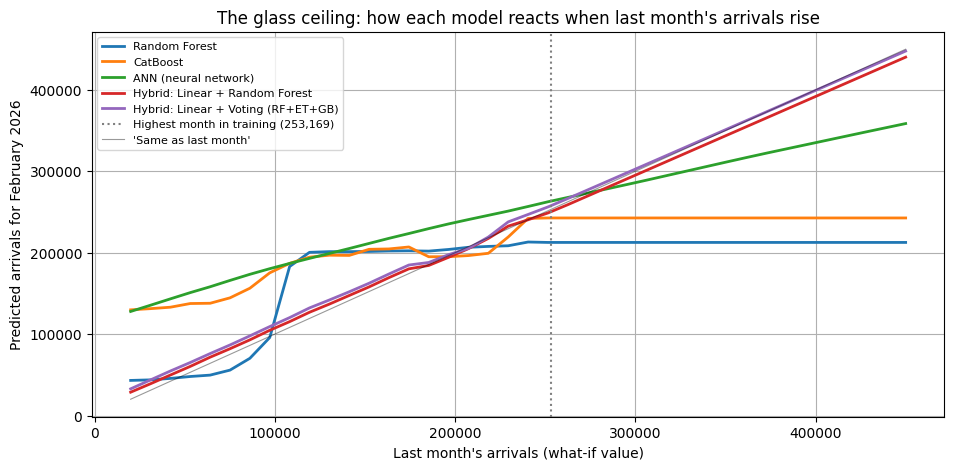

In [11]:
row = test[test["date"] == "2026-02-01"].iloc[0]

def with_lag1(row, v):
    r = row[features].astype(float).copy()
    old = r["lag_1"]
    r["lag_1"] = v
    r["roll3"] = (v + r["lag_2"] + r["lag_3"]) / 3
    r["roll12"] = r["roll12"] + (v - old) / 12
    return r

values = np.linspace(20000, 450000, 40)
show = ["Random Forest", BOOST, "ANN (neural network)", "Hybrid: Linear + Random Forest",
        "Hybrid: Linear + Voting (RF+ET+GB)"]
fitted_show = {n: clone(models[n][1]).fit(X_train, y_train) for n in show}

fig, ax = plt.subplots()
for n in show:
    ys = [float(fitted_show[n].predict(pd.DataFrame([with_lag1(row, v)])[features])[0]) for v in values]
    ax.plot(values, ys, linewidth=2, label=n)
ax.axvline(y_train.max(), color="gray", linestyle=":", label=f"Highest month in training ({y_train.max():,.0f})")
ax.plot(values, values, color="black", linewidth=0.8, alpha=0.4, label="'Same as last month'")
ax.set_xlabel("Last month's arrivals (what-if value)")
ax.set_ylabel("Predicted arrivals for February 2026")
ax.set_title("The glass ceiling: how each model reacts when last month's arrivals rise")
ax.legend(fontsize=8)
plt.show()

**What we see (from this run):**
- The **Random Forest** goes flat: above about 120,000, more tourists last month barely change its prediction (it stays between about 200,000 and 213,000). **CatBoost** goes flat later, at about 243,000. This is the glass ceiling.
- The **ANN** keeps rising, because its layers continue in straight lines, but at a gentler slope than the real change.
- The **hybrids** stay close to the "same as last month" line, because the linear trend part extrapolates, while the tree part adds the seasonal correction.

This is a *controlled experiment*: only one input changed, so the difference between the lines is caused by how each model is built.

## 7. Errors by monsoon season
Does each model do better in some seasons? Average error per season in the test period:

In [12]:
season_test = test["season"].values
rep = {}
for n in ["Random Forest", BOOST, "ANN (neural network)", f"Stacking: RF + {BOOST} + ANN",
          "Hybrid: Linear + Voting (RF+ET+GB)"]:
    rep[n] = pd.Series(np.abs(y_test.values - preds[n])).groupby(season_test).mean().round()
rep["Naive (last month)"] = pd.Series(np.abs(y_test.values - test["lag_1"].values)).groupby(season_test).mean().round()
pd.DataFrame(rep).T

,Inter_monsoon,NE_monsoon,SW_monsoon
Random Forest,35477.0,60306.0,20342.0
CatBoost,24317.0,29756.0,12185.0
ANN (neural network),24947.0,17062.0,15256.0
Stacking: RF + CatBoost + ANN,20874.0,19383.0,13370.0
Hybrid: Linear + Voting (RF+ET+GB),12311.0,13521.0,13595.0
Naive (last month),39473.0,19971.0,33228.0


**What we see (from this run):** the **North-East monsoon (December to February)** contains the record-high months. The raw Random Forest has its biggest error there (about 60,300) and CatBoost about 29,800, while the ANN (about 17,100) and the stacking model (about 19,400) cope much better. The best hybrid has similar errors in all three seasons (about 12,300 to 13,600). This is what the glass ceiling predicts.

## 8. Saving the models (.pkl) and the dashboard
The dashboard loads saved model files (`.pkl`). Here we save our trained models with `joblib` and check that a reloaded model gives the same prediction, which proves the file works.

In [13]:
import joblib
fitted_all = {n: clone(m).fit(X_train, y_train) for n, (fam, m) in models.items()}
joblib.dump(fitted_all, "eval_models_notebook.pkl")

reloaded = joblib.load("eval_models_notebook.pkl")
name = "Hybrid: Linear + Voting (RF+ET+GB)"
same = np.allclose(fitted_all[name].predict(X_test), reloaded[name].predict(X_test))
print("Saved", len(fitted_all), "models. Reloaded model gives identical predictions:", same)

Saved 12 models. Reloaded model gives identical predictions: True


In the dashboard (`dashboard/app.py`), the same model set is loaded from `.pkl` files, or trained on first start if the files are missing. The dashboard then lets a user pick a month, change last month's arrivals or the exchange rate, and see every model's prediction, which turns the experiment in Section 6 into something anyone can try.

## 9. Conclusions of this part
1. **Neural network:** an ANN follows trends better than tree ensembles because it is made of straight-line pieces. It is the strongest single non-linear model on the main test (about 18,800, against about 35,500 for the Random Forest), but it is unstable across time windows (about 36,600 in the 2023 recovery window).
2. **Blends and stacking** help when the members make *different* kinds of mistakes (CatBoost + ANN, and stacking with an ANN inside). Blending a good model with a weak one drags it down (RF + ANN, RF + CatBoost). And they do not fix a weakness that all members share, as the 2023 window shows.
3. **Hybrids with a tree model** remain the most reliable idea in the project: best on the main test and on the five-window average. A hybrid with an ANN on top gave only a small gain (about 18,800 to 18,000). A possible reason (an interpretation, not proven here) is that the ANN already follows the trend, so the linear model leaves little for it to learn.
4. **The glass ceiling experiment** shows the cause of the main finding directly, instead of only arguing it: tree models go flat, while the ANN and the hybrids keep following.

**Limitations (as in the main notebook):** small data (199 months), one-month-ahead forecasts only, fixed model settings without tuning, and stacking built with ordinary 5-fold cross-validation. The ANN depends on a random start, so its numbers can change slightly between runs.